In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split , cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, LabelBinarizer
from sklearn.metrics import classification_report , roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay, confusion_matrix, log_loss

In [2]:
df = pd.read_csv("new_Iris.csv") 
df.head(3)
df.drop(columns=["Unnamed: 0"],axis=1,inplace=True)
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,SepalLengthRatio,PetalLengthRatio,SepalElipseAreaCm2,PetalElipseAreaCm2
0,5.1,3.5,1.4,0.2,Iris-setosa,1.457143,7.0,14.019357,1.539380
1,4.9,3.0,1.4,0.2,Iris-setosa,1.633333,7.0,11.545353,1.539380
2,4.7,3.2,1.3,0.2,Iris-setosa,1.468750,6.5,11.812388,1.327323
3,4.6,3.1,1.5,0.2,Iris-setosa,1.483871,7.5,11.199778,1.767146
4,5.0,3.6,1.4,0.2,Iris-setosa,1.388889,7.0,14.137167,1.539380


In [3]:
X = df.drop(columns=["Species"],axis=1) 
Y = df["Species"]

In [4]:
le = LabelEncoder() 
df.Species = le.fit_transform(df.Species)  
df

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,SepalLengthRatio,PetalLengthRatio,SepalElipseAreaCm2,PetalElipseAreaCm2
0,5.1,3.5,1.4,0.2,0,1.457143,7.000000,14.019357,1.539380
1,4.9,3.0,1.4,0.2,0,1.633333,7.000000,11.545353,1.539380
2,4.7,3.2,1.3,0.2,0,1.468750,6.500000,11.812388,1.327323
3,4.6,3.1,1.5,0.2,0,1.483871,7.500000,11.199778,1.767146
4,5.0,3.6,1.4,0.2,0,1.388889,7.000000,14.137167,1.539380
...,...,...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,2.233333,2.260870,15.786503,21.237166
146,6.3,2.5,5.0,1.9,2,2.520000,2.631579,12.370021,19.634954
147,6.5,3.0,5.2,2.0,2,2.166667,2.600000,15.315264,21.237166
148,6.2,3.4,5.4,2.3,2,1.823529,2.347826,16.556193,22.902210


In [5]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.3,random_state=42) 

sc = StandardScaler() 
x_train_sc = sc.fit_transform(X_train) 
x_test_sc = sc.transform(X_test) 

Model Test Skoru: 1.0
Model Eğitim Skoru: 0.97143
Model Log Loss Oranı: 0.08989

Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: [0.95238095 0.9047619  0.95238095 1.         0.9047619 ]
Ortalama Skor: 0.94286
Skorların Standart Sapması: 0.03563

ROC-AUC Skoru: 1.00

Logistic Regression Sınıflandırma Raporu
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        19
Iris-versicolor       1.00      1.00      1.00        13
 Iris-virginica       1.00      1.00      1.00        13

       accuracy                           1.00        45
      macro avg       1.00      1.00      1.00        45
   weighted avg       1.00      1.00      1.00        45



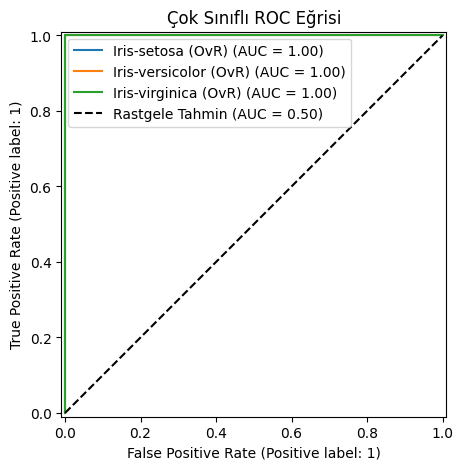

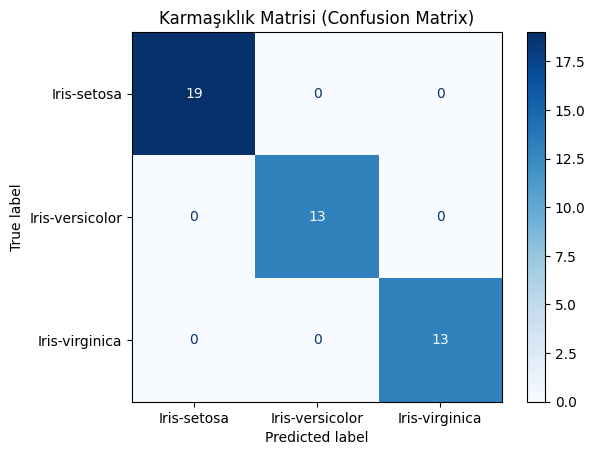

In [6]:
from sklearn.linear_model import LogisticRegression 

logr = LogisticRegression() 

logr.fit(x_train_sc,Y_train) 

logr_predict = logr.predict(x_test_sc) 
logr_pred_prob = logr.predict_proba(x_test_sc) 

logr_score = logr.score(x_test_sc,Y_test) 
logr_train_score = logr.score(x_train_sc,Y_train)

logr_cv_score = cross_val_score(logr,x_train_sc,Y_train,cv=5)

logr_log_loss = log_loss(Y_test,logr_pred_prob)

logr_roc_auc = roc_auc_score(Y_test, logr_pred_prob, multi_class='ovr')

print(f"Model Test Skoru: {logr_score}") 
print(f"Model Eğitim Skoru: {logr_train_score:.5f}") 
print(f"Model Log Loss Oranı: {logr_log_loss:.5f}") 
print(f"""
Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: {logr_cv_score}
Ortalama Skor: {logr_cv_score.mean():.5f}
Skorların Standart Sapması: {logr_cv_score.std():.5f}
""") 
print(f"ROC-AUC Skoru: {logr_roc_auc:.2f}\n")

print("Logistic Regression Sınıflandırma Raporu\n",classification_report(Y_test,logr_predict)) 

lb = LabelBinarizer().fit(Y_train) 
y_test_bin = lb.transform(Y_test) 

(fig,ax) = plt.subplots(figsize=(7,5)) 

for i,classname in enumerate(lb.classes_): 
    RocCurveDisplay.from_predictions(
        y_test_bin[:,i],
        logr_pred_prob[:,i],
        name=f"{classname} (OvR)",
        ax=ax
    )

plt.plot([0, 1], [0, 1], "k--", label="Rastgele Tahmin (AUC = 0.50)")
plt.title("Çok Sınıflı ROC Eğrisi")
plt.legend()
plt.show()

cm = confusion_matrix(Y_test, logr_predict)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logr.classes_)
disp.plot(cmap="Blues")
plt.title("Karmaşıklık Matrisi (Confusion Matrix)")
plt.show()

In [7]:
from sklearn.tree import DecisionTreeClassifier 

dtc = DecisionTreeClassifier(class_weight='balanced',min_samples_leaf=5,max_depth=5,random_state=42) 

dtc.fit(X_train,Y_train)

dtc_pred = dtc.predict(X_test) 
dtc_pred_prob = dtc.predict_proba(X_test)

Model Test Skoru: 1.0
Model Eğitim Skoru: 0.94286
Model Log Loss Oranı: 0.01540

Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: [1.         0.9047619  0.85714286 1.         0.9047619 ]
Ortalama Skor: 0.93333
Skorların Standart Sapması: 0.05714

ROC-AUC Skoru: 1.00

Decision Tree Classifier Raporu
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        19
Iris-versicolor       1.00      1.00      1.00        13
 Iris-virginica       1.00      1.00      1.00        13

       accuracy                           1.00        45
      macro avg       1.00      1.00      1.00        45
   weighted avg       1.00      1.00      1.00        45



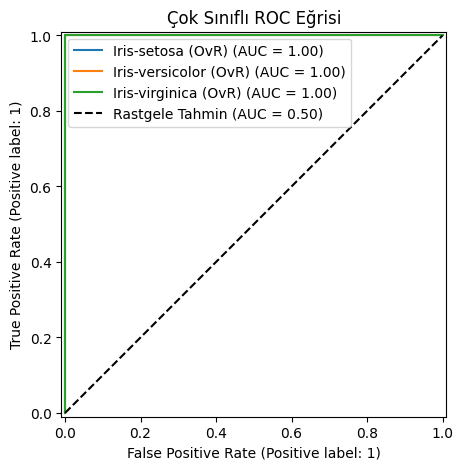

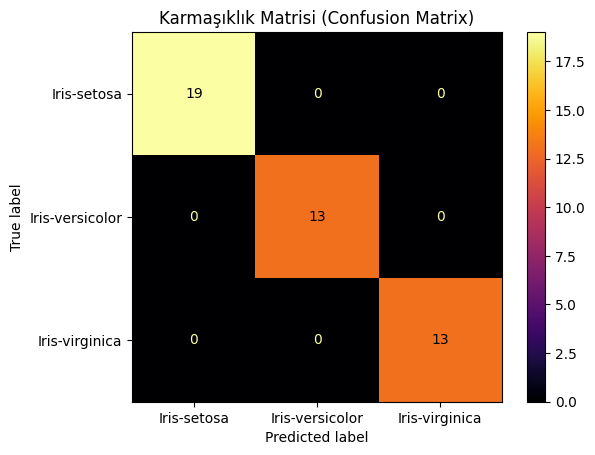

In [8]:
dtc_score = dtc.score(X_test,Y_test) 
dtc_train_score = dtc.score(X_train,Y_train) 
dtc_log_loss = log_loss(Y_test,dtc_pred_prob) 

dtc_cv = cross_val_score(dtc,X_train,Y_train,cv=5) 

dtc_roc_auc = roc_auc_score(Y_test,dtc_pred_prob,average='macro',multi_class='ovr') 

dtc_cr = classification_report(Y_test,dtc_pred)  

dtc_lb = LabelBinarizer().fit(Y_train) 
dtc_y_lb = dtc_lb.transform(Y_test) 

print(f"Model Test Skoru: {dtc_score}") 
print(f"Model Eğitim Skoru: {dtc_train_score:.5f}") 
print(f"Model Log Loss Oranı: {dtc_log_loss:.5f}") 
print(f"""
Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: {dtc_cv}
Ortalama Skor: {dtc_cv.mean():.5f}
Skorların Standart Sapması: {dtc_cv.std():.5f}
""") 
print(f"ROC-AUC Skoru: {dtc_roc_auc:.2f}\n")

print("Decision Tree Classifier Raporu\n",dtc_cr) 

(fig,ax) = plt.subplots(figsize=(7,5)) 

for i,classname in enumerate(dtc_lb.classes_): 
    RocCurveDisplay.from_predictions(
        dtc_y_lb[:,i],
        dtc_pred_prob[:,i],
        name=f"{classname} (OvR)",
        ax=ax
    )

plt.plot([0, 1], [0, 1], "k--", label="Rastgele Tahmin (AUC = 0.50)")
plt.title("Çok Sınıflı ROC Eğrisi")
plt.legend()
plt.show()

cm = confusion_matrix(Y_test, dtc_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dtc.classes_)
disp.plot(cmap="inferno")
plt.title("Karmaşıklık Matrisi (Confusion Matrix)")
plt.show()

In [9]:
from sklearn.ensemble import RandomForestClassifier 

rfc = RandomForestClassifier(n_estimators=400,min_samples_split=3,min_samples_leaf=2,class_weight='balanced',max_depth=5)

rfc.fit(X_train,Y_train)

rfc_pred = rfc.predict(X_test) 
rfc_pred_prob = rfc.predict_proba(X_test)

Model Test Skoru: 1.0
Model Eğitim Skoru: 0.97143
Model Log Loss Oranı: 0.05642

Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: [0.95238095 0.9047619  0.9047619  1.         0.95238095]
Ortalama Skor: 0.94286
Skorların Standart Sapması: 0.03563

ROC-AUC Skoru: 1.00

Random Forest Classifier Raporu
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        19
Iris-versicolor       1.00      1.00      1.00        13
 Iris-virginica       1.00      1.00      1.00        13

       accuracy                           1.00        45
      macro avg       1.00      1.00      1.00        45
   weighted avg       1.00      1.00      1.00        45



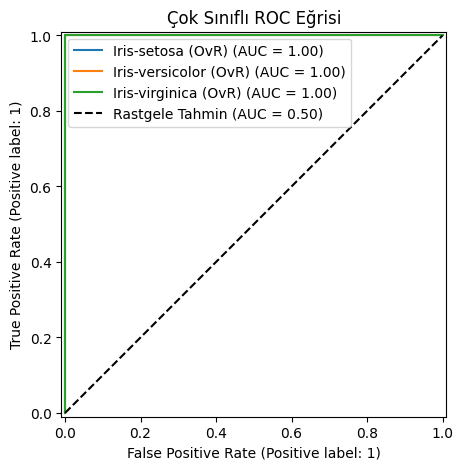

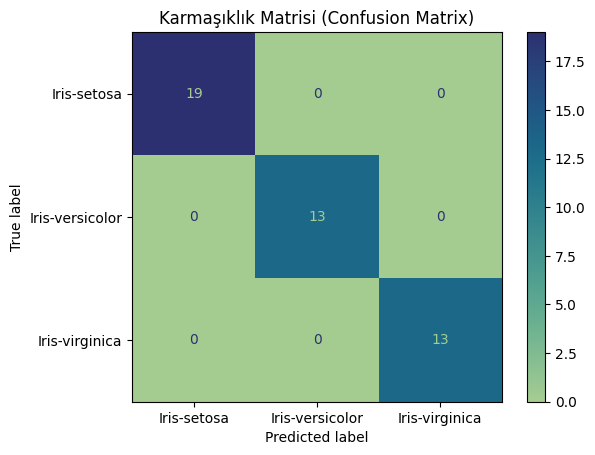

In [10]:
rfc_score = rfc.score(X_test,Y_test) 
rfc_train_sc = rfc.score(X_train,Y_train) 

rfc_log_loss = log_loss(Y_test,rfc_pred_prob) 

rfc_cv = cross_val_score(rfc,X_train,Y_train,cv=5) 

rfc_roc_auc = roc_auc_score(Y_test,rfc_pred_prob,multi_class='ovr',average='macro') 

rfc_cr = classification_report(Y_test,rfc_pred) 

rfc_lb = LabelBinarizer().fit(Y_train) 
rfc_y_lb = rfc_lb.transform(Y_test)  

print(f"Model Test Skoru: {rfc_score}") 
print(f"Model Eğitim Skoru: {rfc_train_sc:.5f}") 
print(f"Model Log Loss Oranı: {rfc_log_loss:.5f}") 
print(f"""
Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: {rfc_cv}
Ortalama Skor: {rfc_cv.mean():.5f}
Skorların Standart Sapması: {rfc_cv.std():.5f}
""") 
print(f"ROC-AUC Skoru: {rfc_roc_auc:.2f}\n")

print("Random Forest Classifier Raporu\n",rfc_cr) 

(fig,ax) = plt.subplots(figsize=(7,5)) 

for i,classname in enumerate(rfc_lb.classes_): 
    RocCurveDisplay.from_predictions(
        rfc_y_lb[:,i],
        rfc_pred_prob[:,i],
        name=f"{classname} (OvR)",
        ax=ax
    )

plt.plot([0, 1], [0, 1], "k--", label="Rastgele Tahmin (AUC = 0.50)")
plt.title("Çok Sınıflı ROC Eğrisi")
plt.legend()
plt.show()

cm = confusion_matrix(Y_test, rfc_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rfc.classes_)
disp.plot(cmap="crest")
plt.title("Karmaşıklık Matrisi (Confusion Matrix)")
plt.show()

In [11]:
from sklearn.neighbors import KNeighborsClassifier 

knc = KNeighborsClassifier() 

knc.fit(x_train_sc,Y_train) 

knn_predict = knc.predict(x_test_sc) 
knn_predict_proba = knc.predict_proba(x_test_sc) 

Model Test Skoru: 0.9777777777777777
Model Eğitim Skoru: 0.94286
Model Log Loss Oranı: 0.08417

Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: [0.95238095 0.9047619  0.85714286 1.         0.85714286]
Ortalama Skor: 0.91429
Skorların Standart Sapması: 0.05553

ROC-AUC Skoru: 1.00

K Nearest Neighbors (KNN) Classifier Raporu
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        19
Iris-versicolor       1.00      0.92      0.96        13
 Iris-virginica       0.93      1.00      0.96        13

       accuracy                           0.98        45
      macro avg       0.98      0.97      0.97        45
   weighted avg       0.98      0.98      0.98        45



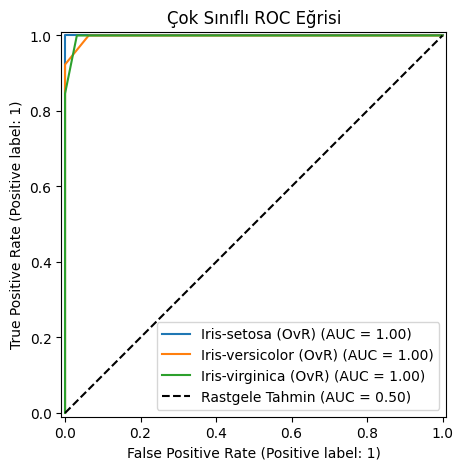

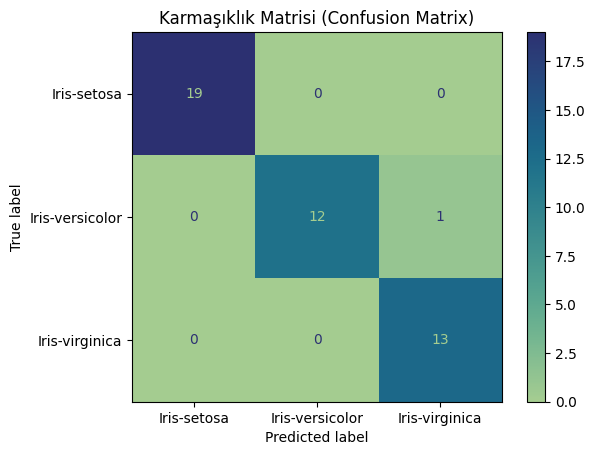

In [13]:
knn_score = knc.score(x_test_sc,Y_test) 
knn_train_score = knc.score(x_train_sc,Y_train) 
knn_log_loss = log_loss(Y_test,knn_predict_proba) 

knn_cv = cross_val_score(knc,x_train_sc,Y_train,cv=5) 
knn_roc_auc = roc_auc_score(Y_test,knn_predict_proba,multi_class='ovr',average='macro') 

knn_cr = classification_report(Y_test,knn_predict) 

knn_lb = LabelBinarizer().fit(Y_train) 
knn_y_lb = knn_lb.transform(Y_test) 

(fig,ax) = plt.subplots(figsize=(7,5)) 

print(f"Model Test Skoru: {knn_score}") 
print(f"Model Eğitim Skoru: {knn_train_score:.5f}") 
print(f"Model Log Loss Oranı: {knn_log_loss:.5f}") 
print(f"""
Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: {knn_cv}
Ortalama Skor: {knn_cv.mean():.5f}
Skorların Standart Sapması: {knn_cv.std():.5f}
""") 
print(f"ROC-AUC Skoru: {knn_roc_auc:.2f}\n")

print("K Nearest Neighbors (KNN) Classifier Raporu\n",knn_cr) 

for i,classname in enumerate(knn_lb.classes_): 
    RocCurveDisplay.from_predictions(
        knn_y_lb[:,i],
        knn_predict_proba[:,i],
        name=f"{classname} (OvR)",
        ax=ax
    )

plt.plot([0, 1], [0, 1], "k--", label="Rastgele Tahmin (AUC = 0.50)")
plt.title("Çok Sınıflı ROC Eğrisi")
plt.legend()
plt.show()

cm = confusion_matrix(Y_test, knn_predict)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn_lb.classes_)
disp.plot(cmap="crest")
plt.title("Karmaşıklık Matrisi (Confusion Matrix)")
plt.show()

In [51]:
from sklearn.svm import SVC 

svc = SVC(C=2.0,kernel='poly',degree=3,gamma='scale',class_weight='balanced',probability=True) 

svc.fit(x_train_sc,Y_train) 

svc_predict = svc.predict(x_test_sc) 
svc_pred_prob = svc.predict_proba(x_test_sc)

Model Test Skoru: 0.9777777777777777
Model Eğitim Skoru: 0.95238
Model Log Loss Oranı: 0.14070

Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: [0.9047619  0.80952381 0.9047619  1.         0.85714286]
Ortalama Skor: 0.89524
Skorların Standart Sapması: 0.06317

ROC-AUC Skoru: 1.00

Support Vector Regression (SVC) Classifier Raporu
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        19
Iris-versicolor       0.93      1.00      0.96        13
 Iris-virginica       1.00      0.92      0.96        13

       accuracy                           0.98        45
      macro avg       0.98      0.97      0.97        45
   weighted avg       0.98      0.98      0.98        45



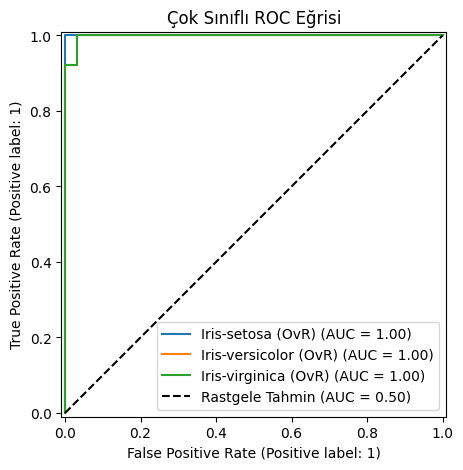

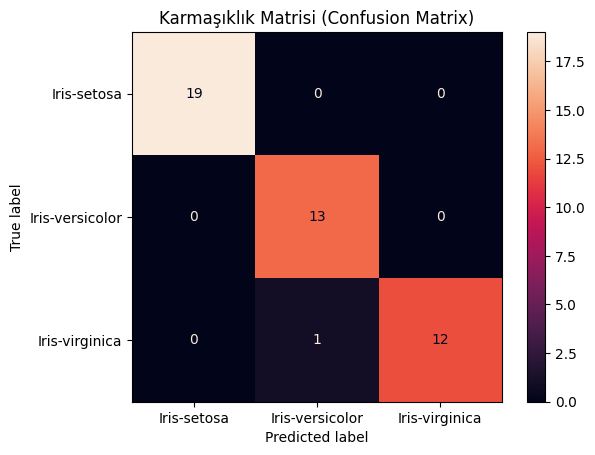

In [52]:
svc_score = svc.score(x_test_sc,Y_test) 
svc_train_score = svc.score(x_train_sc,Y_train) 
svc_log_loss = log_loss(Y_test,svc_pred_prob) 

svc_cv = cross_val_score(svc,x_train_sc,Y_train,cv=5)
svc_roc_auc = roc_auc_score(Y_test,svc_pred_prob,multi_class='ovr',average='macro') 
svc_cr = classification_report(Y_test,svc_predict) 
svc_cm = confusion_matrix(Y_test,svc_predict)

print(f"Model Test Skoru: {svc_score}") 
print(f"Model Eğitim Skoru: {svc_train_score:.5f}") 
print(f"Model Log Loss Oranı: {svc_log_loss:.5f}") 
print(f"""
Çapraz Doğrulama Raporu:
Her Katmanın Doğruluk Oranı: {svc_cv}
Ortalama Skor: {svc_cv.mean():.5f}
Skorların Standart Sapması: {svc_cv.std():.5f}
""") 
print(f"ROC-AUC Skoru: {svc_roc_auc:.2f}\n")

print("Support Vector Regression (SVC) Classifier Raporu\n",svc_cr) 

(fig,ax) = plt.subplots(figsize=(7,5))

svc_lb = LabelBinarizer().fit(Y_train) 
svc_y_lb = svc_lb.transform(Y_test) 

for i,classname in enumerate(svc_lb.classes_): 
    RocCurveDisplay.from_predictions(
        svc_y_lb[:,i],
        svc_pred_prob[:,i],
        name=f"{classname} (OvR)",
        ax=ax 
    )

plt.plot([0, 1], [0, 1], "k--", label="Rastgele Tahmin (AUC = 0.50)")
plt.title("Çok Sınıflı ROC Eğrisi")
plt.legend()
plt.show()

disp = ConfusionMatrixDisplay(confusion_matrix=svc_cm, display_labels=svc_lb.classes_)
disp.plot(cmap="rocket")
plt.title("Karmaşıklık Matrisi (Confusion Matrix)")
plt.show()